# 기능 C 게임 그림체 홍보 이미지 (IP-Adapter, 게임 3개 연결) (10/27)

게임 참조 이미지의 그림체를 유지하면서 요청한 장면의 홍보 이미지(글자 없음)를 만든다. 10/21 결정대로 IP-Adapter를 쓰고(img2img 안 씀), 게임별 설정은 B 배너에서 10/26에 정한 것을 그대로 쓴다. 07의 설정을 이 노트북 안에 다시 넣었다(값은 07과 같다).

| 게임 | 프롬프트 | IP-Adapter | 근거 |
|---|---|---|---|
| 냥기사 | 줄인 캐릭터 태그(`NAI_SHORT`) + `safe` + 장면 + 품질 태그 | 전체 층, 강도 0.5 | 07 "배너 문제 수정 실험" T (나), 10/26 냥기사 방식 결정 |
| KayKit | `3d, low poly, render` + 게임 태그 + `safe` + 장면 + 품질 태그, 부정에 `anime, 1girl` | 그림체 블록(`up.block_0`) | 07 K (a) |
| 0x72 | 게임 태그 + `safe` + Compel `(장면)1.3` + 품질 태그 | 전체 층, 강도 0.5 | 07 X (b) |

- 세 게임 모두 부정 프롬프트에 `nsfw`를 더한다(07 "F2. 0x72 rating 태그", 10/26 결정).
- 전체 층 강도는 07 "설정"과 같이 05 `ipa_gen_summary.csv`의 animagine_xl4 게임별 그림체 점수 최고값으로 정한다.
- 입력 장면: 07 "R2. 판촉 표현 수정 후보 비교"에서 한국어 요청 18건(게임마다 6건)을 Qwen3-VL-8B가 바꾼 영어 장면 태그(`current` 방식, seed 0)를 그대로 쓴다. 실제 사용 흐름(한국어 요청 → 장면 태그 → 이미지)의 입력과 같다.
- 비교: 같은 프롬프트·seed로 IP-Adapter 끔(강도 0)을 함께 만들어, 그림체 유지가 IP-Adapter 덕분인지 확인한다.
- 생성 설정: 07과 같다(animagine-xl-4.0, Euler Ancestral 28스텝, CFG 5, 1216×832, bf16, seed 0·1).
- 지표: 07 "F. 지표·그림"과 같다.
  - `style_sim`: 게임 원본 이미지 100장(참조 이미지 제외, 무작위 seed 0)과의 CLIP 평균 유사도
  - `scene_sim`: 장면 태그 문장과의 CLIP 유사도
  - `two_cat_prob`(냥기사), `exposed_prob`: CLIP 제로샷. 위 실험에서 틀린 경우가 있어 그림으로 함께 확인한다.
- 기록 (`outputs/promo_c/`)
  - `c_config.json`: 게임별 설정(프롬프트 형식, 부정 프롬프트, IP-Adapter 설정, 참조 이미지), 입력 장면 18건, 생성 설정, 패키지 버전, GPU
  - `c_records.csv`: 이미지 1장마다 게임·요청·장면·seed·IP-Adapter 켬/끔·프롬프트·부정 프롬프트·토큰 수·잘림 여부·생성 시간·최대 VRAM·오류
  - `c_runs.csv`: 실행마다 시작·종료 시각, 모델 로드 시간, 전체 시간, 생성 장수, 최대 VRAM
  - `c_scored.csv`, `c_summary.csv`, `c_scores.png`, `c_grid_nai.png`, `c_grid_kaykit.png`, `c_grid_x72.png`
- 실행 순서: 위에서부터 차례로 실행한다. 다시 실행하면 오류 없이 만든 이미지는 건너뛴다.
- 예상 시간: 18건 × seed 2개 × 켬/끔 2개 = 72장. 07 F에서 이 설정의 장당 생성 시간이 10.4~10.5초였다(`final_records.csv`) → 약 13분 + 모델 로드.
- GPU를 다른 노트북(10, 11)과 동시에 쓰지 않는다.

## 설정

In [1]:
import gc
import importlib.metadata
import json
import os
import platform
import re
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
FIX_DIR = ROOT / 'outputs' / 'banner_fix'
OUT_DIR = ROOT / 'outputs' / 'promo_c'
OUT_DIR.mkdir(parents=True, exist_ok=True)
REC_CSV = OUT_DIR / 'c_records.csv'
RUNS_CSV = OUT_DIR / 'c_runs.csv'

# 07 "설정"과 같은 모델·IP-Adapter·참조 이미지·태그
MODEL = 'cagliostrolab/animagine-xl-4.0'
IPA = dict(repo='h94/IP-Adapter', subfolder='sdxl_models', weight_name='ip-adapter_sdxl.bin')
REFS = {'nai': RAW / 'nai' / 'lora_gen' / 'gen_0053_protagonist.png',
        'kaykit': RAW / 'kaykit' / 'renders' / 'kk_0185.png',
        'x72': RAW / 'pixel_0x72' / 'scenes' / 'x72_scene_0454.png'}
GAME_TAGS = {
    'nai': ('no humans, black cat adventurer, yellow eyes, red wide-brim hat, ears through headwear, olive green capelet, '
            'brown cross-shaped clasp, brown belt, short sword at hip, olive green cape with shield emblem, '
            'flat color, cel shading, clean thin lineart, soft bright colors, storybook fantasy, anime style'),
    'kaykit': 'low poly 3d game character render, knight',
    'x72': 'pixel art, 16-bit dungeon',
}
QUALITY = 'masterpiece, high score, great score, absurdres'
NEGATIVE = 'text, letters, words, watermark, signature, logo, lowres, worst quality, bad quality'
W, H = 1216, 832
STEPS, CFG = 28, 5.0
SEEDS = [0, 1]

# 07 "배너 문제 수정 실험" 설정과 같은 값
STYLE_ONLY = {'up': {'block_0': [0.0, 1.0, 0.0]}}
NAI_SHORT = 'no humans, black cat adventurer, yellow eyes, red wide-brim hat, olive green capelet, olive green cape with shield emblem'
ipa_sum = pd.read_csv(ROOT / 'outputs' / 'ipa_compare' / 'ipa_gen_summary.csv', encoding='utf-8-sig')
ipa_sum = ipa_sum[ipa_sum.model == 'animagine_xl4']
SCALE = ipa_sum.loc[ipa_sum.groupby('game').style_sim.idxmax()].set_index('game').scale.to_dict()
print('게임별 전체 층 강도(05 style_sim 최대):', SCALE)

# 10/26 결정: 게임별 프롬프트·IP-Adapter, rating 태그(긍정 safe, 부정 nsfw)
GAME_CFG = {
    'nai': dict(prompt=lambda s: f'{NAI_SHORT}, safe, {s}, {QUALITY}', negative=NEGATIVE + ', nsfw',
                ipa=SCALE['nai'], ipa_name='all_layers', compel=False),
    'kaykit': dict(prompt=lambda s: f"3d, low poly, render, {GAME_TAGS['kaykit']}, safe, {s}, {QUALITY}",
                   negative=NEGATIVE + ', anime, 1girl, nsfw', ipa=STYLE_ONLY, ipa_name='style_only', compel=False),
    'x72': dict(prompt=lambda s: f"{GAME_TAGS['x72']}, safe, ({s})1.3, {QUALITY}", negative=NEGATIVE + ', nsfw',
                ipa=SCALE['x72'], ipa_name='all_layers', compel=True),
}
# 07 F와 같은 프롬프트인지 확인 (F의 safe 조건 기록과 비교)
_f = pd.read_csv(FIX_DIR / 'final_records.csv', keep_default_na=False)
_f = _f[_f.rating == 'safe']
_f_name = {'nai': ('nai_short_tags', 'all_layers'), 'kaykit': ('kaykit_lowpoly_neg', 'style_only'),
           'x72': ('x72_compel_weight', 'all_layers')}
_req1 = pd.read_csv(ROOT / 'outputs' / 'banner_request' / 'request_records.csv').set_index('item')
for g, (n, m) in _f_name.items():
    r = _f[(_f['name'] == n) & (_f['mode'] == m)].iloc[0]
    assert GAME_CFG[g]['prompt'](_req1.loc[r['item'], 'scene']) == r.prompt and GAME_CFG[g]['negative'] == r.negative, g
print('07 F safe 조건과 프롬프트·부정 프롬프트 같음')

# 입력 장면: 07 R2의 Qwen 결과(current, seed 0)에서 장면 태그를 꺼냄
r2 = pd.read_csv(FIX_DIR / 'promo_fix_records.csv', keep_default_na=False)
r2 = r2[(r2.method == 'current') & (r2.seed == 0)]


def scene_of(raw):
    m = re.search(r'\{.*\}', raw, re.S)
    return json.loads(m.group(0))['scene']


SCENES = pd.DataFrame(dict(item=r2['item'], game=r2.game, request=r2.request, scene=r2.raw.map(scene_of))).reset_index(drop=True)
assert len(SCENES) == 18 and SCENES.scene.str.len().gt(0).all()
assert SCENES.game.value_counts().eq(6).all()
pd.set_option('display.max_colwidth', 120)
display(SCENES)

게임별 전체 층 강도(05 style_sim 최대): {'kaykit': 0.8, 'nai': 0.5, 'x72': 0.5}
07 F safe 조건과 프롬프트·부정 프롬프트 같음


,item,game,request,scene
0,B0,nai,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,"summer beach, sunset, waves, palm trees, sandy shore, horizon, blue sky, gentle breeze"
1,B1,nai,"할로윈 분위기로 밤 숲에서 이벤트 배너, 신규 의상 업데이트 알려줘","moonlit forest, glowing pumpkins, misty path, autumn leaves, black cat knight, eerie trees"
2,B2,kaykit,"성 앞마당에서 기사가 깃발 든 느낌으로 신규 영웅 업데이트 배너, 버전 1.2, 11월 1일 출시","castle courtyard, knight standing, flag waving, medieval fantasy, open plaza, stone architecture"
3,B3,kaykit,"눈 내리는 겨울 마을 배경으로 겨울 이벤트 배너 만들어줘, 30% 할인","snowy village, winter trees, glowing lanterns, frozen river, cozy cabin, soft snowfall"
4,B4,x72,"금화가 가득한 보물방 배경으로 던전 확장팩 출시 기념 30% 할인 배너, 11월 5일까지","pixel dungeon, treasure room, gold coins, glowing artifacts, ancient stone walls, torchlight, map scroll, locked che..."
5,B5,x72,용암 던전 배경으로 보스 레이드 이벤트 배너 만들어줘,"lava dungeon, pixel art, fiery cavern, glowing magma, dungeon corridor, boss fight, dark stone walls, pixelated torc..."
6,B6,nai,벚꽃 핀 봄 언덕에서 냥기사 신규 스킨 공개 배너 만들어줘,"spring_hill, cherry_blossom, soft_light, gentle_wind, cat_knight, peaceful_landscape"
7,B7,nai,"눈 오는 크리스마스 마을 배경으로 냥기사 겨울 업데이트 배너, 12월 20일 업데이트","snowy village, christmas lights, cat knight, winter landscape, frozen trees, cozy rooftops"
8,B8,nai,"바다 위 배에서 냥기사 해적 의상 20% 할인 배너, 이번 주말까지","ship at sea, black cat knight, stormy ocean, wooden deck, pirate hat, sword in hand"
9,B9,nai,도서관 배경으로 냥기사 스토리 2장 공개 배너,"library, bookshelves, candlelight, parchment, wooden floor, old windows, quiet atmosphere, fantasy setting"


## 생성 (게임 3개 × 요청 6건 × seed 2개 × IP-Adapter 켬/끔)

In [2]:
import torch
from compel import CompelForSDXL
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


# 보고서용 실험 설정 기록
config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), model=MODEL, ip_adapter=IPA, refs={g: str(p) for g, p in REFS.items()},
    games={g: dict(prompt_example=c['prompt']('{scene}'), negative=c['negative'], ipa=c['ipa'], ipa_name=c['ipa_name'],
                   compel=c['compel']) for g, c in GAME_CFG.items()},
    scale_source='05 ipa_gen_summary.csv animagine_xl4 게임별 style_sim 최대', compare='IP-Adapter 켬 / 끔(강도 0), 같은 프롬프트·seed',
    scenes=SCENES.to_dict('records'), scene_source='07 R2 promo_fix_records.csv (method current, seed 0)',
    gen=dict(width=W, height=H, steps=STEPS, cfg=CFG, seeds=SEEDS, scheduler='EulerAncestral', dtype='bfloat16'),
    versions={p: pkg_version(p) for p in ['torch', 'diffusers', 'transformers', 'compel', 'accelerate', 'pillow', 'pandas',
                                          'numpy']},
    python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'c_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1), encoding='utf-8')
print('설정 기록: c_config.json | GPU:', config['gpu'], '| diffusers', config['versions']['diffusers'])


# 기능 C 함수: 게임·장면·seed → 홍보 이미지 (게임별 설정은 GAME_CFG)
def make_promo(pipe, compel, game, scene, seed, use_ipa=True):
    c = GAME_CFG[game]
    prompt = c['prompt'](scene)
    pipe.set_ip_adapter_scale(c['ipa'] if use_ipa else 0.0)
    if c['compel']:
        e = compel(prompt, negative_prompt=c['negative'])
        kw = dict(prompt_embeds=e.embeds, pooled_prompt_embeds=e.pooled_embeds,
                  negative_prompt_embeds=e.negative_embeds, negative_pooled_prompt_embeds=e.negative_pooled_embeds)
    else:
        kw = dict(prompt=prompt, negative_prompt=c['negative'])
    img = pipe(**kw, ip_adapter_image=Image.open(REFS[game]).convert('RGB'), width=W, height=H,
               num_inference_steps=STEPS, guidance_scale=CFG, generator=torch.Generator('cpu').manual_seed(seed)).images[0]
    return img, prompt


recs = {x['file']: x for x in pd.read_csv(REC_CSV, keep_default_na=False).to_dict('records')} if REC_CSV.exists() else {}
todo = [(r, s, u) for r in SCENES.itertuples() for s in SEEDS for u in [True, False]
        if not (recs.get(f"C_{r.item}_{r.game}_{'ipa' if u else 'noipa'}_s{s}.png", {}).get('error', 'x') == ''
                and (OUT_DIR / f"C_{r.item}_{r.game}_{'ipa' if u else 'noipa'}_s{s}.png").exists())]
print('생성할 이미지', len(todo), '장 (전체', len(SCENES) * len(SEEDS) * 2, '장)')
if todo:
    started = time.strftime('%Y-%m-%d %H:%M:%S')
    t_all = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()
    pipe = StableDiffusionXLPipeline.from_pretrained(MODEL, torch_dtype=torch.bfloat16)
    pipe.load_ip_adapter(IPA['repo'], subfolder=IPA['subfolder'], weight_name=IPA['weight_name'])
    pipe.to('cuda')
    pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
    compel = CompelForSDXL(pipe)
    load_sec = round(time.perf_counter() - t_all, 1)
    print('모델 로드', load_sec, '초', flush=True)
    n_ok = 0
    for r, s, use_ipa in todo:
        f = f"C_{r.item}_{r.game}_{'ipa' if use_ipa else 'noipa'}_s{s}.png"
        c = GAME_CFG[r.game]
        prompt = c['prompt'](r.scene)
        n_tok = len(pipe.tokenizer(prompt).input_ids)
        rec = dict(file=f, item=r.item, game=r.game, request=r.request, scene=r.scene, seed=s, use_ipa=use_ipa,
                   ipa=json.dumps(c['ipa'] if use_ipa else 0.0), ipa_name=c['ipa_name'] if use_ipa else 'off',
                   prompt=prompt, negative=c['negative'], compel=c['compel'], n_tokens=n_tok,
                   truncated=n_tok > pipe.tokenizer.model_max_length and not c['compel'], error='')
        try:
            torch.cuda.reset_peak_memory_stats()
            t0 = time.perf_counter()
            img, _ = make_promo(pipe, compel, r.game, r.scene, s, use_ipa)
            rec['gen_sec'] = round(time.perf_counter() - t0, 2)
            rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
            img.save(OUT_DIR / f)
            n_ok += 1
        except Exception as ex:
            rec['error'] = f'{type(ex).__name__}: {ex}'[:300]
        recs[f] = rec
        pd.DataFrame(list(recs.values())).to_csv(REC_CSV, index=False, encoding='utf-8')
        print(f, rec.get('gen_sec'), rec['n_tokens'], rec['error'][:100], flush=True)
    run = dict(started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'), load_sec=load_sec,
               sec_total=round(time.perf_counter() - t_all, 1), n_todo=len(todo), n_ok=n_ok,
               peak_vram_gb=pd.DataFrame(list(recs.values())).get('peak_vram_gb', pd.Series(dtype=float)).max())
    pd.DataFrame([run]).to_csv(RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False, encoding='utf-8-sig')
    print(run)
    del pipe, compel
    gc.collect()
    torch.cuda.empty_cache()
cr = pd.read_csv(REC_CSV, keep_default_na=False)
print('생성', (cr.error == '').sum(), '/', len(cr), '| 오류', (cr.error != '').sum(), '| 77토큰 잘림', cr.truncated.astype(str).eq('True').sum())

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1028 09:09:02.649000 63928 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1028 09:09:02.745000 63928 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Multiple distributions found for package optimum. Picked distribution: optimum
Unable to import `torchao` Tensor objects. This may affect loading 

설정 기록: c_config.json | GPU: NVIDIA GeForce RTX 3090, 24576 MiB, 610.88 | diffusers 0.41.0.dev0
생성할 이미지 72 장 (전체 72 장)


c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading weights: 100%|██████████| 776/776 [00:04<00:00, 159.59it/s]
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


모델 로드 17.5 초


100%|██████████| 28/28 [00:09<00:00,  2.98it/s]


C_B0_nai_ipa_s0.png 10.23 64 


... (138 outputs left out)

100%|██████████| 28/28 [00:09<00:00,  2.83it/s]


C_B17_x72_ipa_s1.png 10.66 52 


100%|██████████| 28/28 [00:09<00:00,  2.82it/s]


C_B17_x72_noipa_s1.png 11.07 52 
{'started': '2026-10-28 09:09:15', 'ended': '2026-10-28 09:21:57', 'load_sec': 17.5, 'sec_total': 762.3, 'n_todo': 72, 'n_ok': 72, 'peak_vram_gb': np.float64(13.03)}
생성 72 / 72 | 오류 0 | 77토큰 잘림 0


## 지표

In [3]:
import torch
from transformers import CLIPModel, CLIPProcessor

# 07 "F. 지표·그림"과 같은 CLIP·기준
CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


def unit(e):
    e = feat(e).float().cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


def embed_images(paths, bs=16):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), bs):
            x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
            out.append(unit(clip.get_image_features(**x)))
    return np.concatenate(out)


def embed_texts(texts):
    with torch.no_grad():
        t = clip_proc(text=texts, return_tensors='pt', padding=True, truncation=True).to('cuda')
        return unit(clip.get_text_features(**t))


def zero_shot(E, texts):
    logits = 100 * E @ embed_texts(texts).T
    return (np.exp(logits) / np.exp(logits).sum(1, keepdims=True))[:, 1]


GAME_FILES = {'nai': sorted((RAW / 'nai' / 'lora_gen').glob('*.png')),
              'kaykit': sorted((RAW / 'kaykit' / 'renders').glob('kk_*.png')),
              'x72': sorted((RAW / 'pixel_0x72' / 'scenes').glob('x72_scene_*.png'))}
rng = np.random.default_rng(0)
HELD = {}
for g, fs in GAME_FILES.items():
    pool = [p for p in fs if p.name != REFS[g].name]
    HELD[g] = embed_images([pool[i] for i in rng.choice(len(pool), 100, replace=False)])
# 참고: 게임 원본끼리의 평균 유사도 (그림체 점수 기준선)
held_base = {g: float((E_ @ E_.T)[~np.eye(len(E_), dtype=bool)].mean()) for g, E_ in HELD.items()}
print('게임 원본 100장끼리 평균 유사도:', {g: round(v, 3) for g, v in held_base.items()})

cs = pd.read_csv(REC_CSV, keep_default_na=False)
cs = cs[cs.error == ''].reset_index(drop=True)
cs['use_ipa'] = cs.use_ipa.astype(str) == 'True'
E = embed_images([OUT_DIR / f for f in cs.file])
SCENE_E = dict(zip(SCENES['item'], embed_texts(list(SCENES.scene))))
cs['style_sim'] = [float((HELD[g] @ e).mean()) for e, g in zip(E, cs.game)]
cs['scene_sim'] = [float(SCENE_E[it] @ e) for e, it in zip(E, cs['item'])]
cs['two_cat_prob'] = np.where(cs.game == 'nai', zero_shot(E, ['a picture of one black cat', 'a picture of two black cats']), np.nan)
cs['exposed_prob'] = zero_shot(E, ['a character wearing modest clothes or armor',
                                   'a character wearing revealing clothes with exposed skin'])
cs.to_csv(OUT_DIR / 'c_scored.csv', index=False, encoding='utf-8-sig')
summary = cs.groupby(['game', 'use_ipa']).agg(
    n=('file', 'size'), style_sim=('style_sim', 'mean'), style_std=('style_sim', 'std'), scene_sim=('scene_sim', 'mean'),
    scene_std=('scene_sim', 'std'), two_cat_prob=('two_cat_prob', 'mean'), exposed_prob=('exposed_prob', 'mean'),
    exposed_max=('exposed_prob', 'max'), gen_sec=('gen_sec', 'mean')).round(4)
summary['held_base'] = summary.index.get_level_values('game').map(held_base).values.round(4)
summary.to_csv(OUT_DIR / 'c_summary.csv', encoding='utf-8-sig')
display(summary)
print('요청별 그림체 점수 (seed 평균, IP-Adapter 켬 - 끔)')
diff = cs.pivot_table(index=['game', 'item'], columns='use_ipa', values='style_sim')
diff['ipa_minus_off'] = diff[True] - diff[False]
display(diff.round(4))

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 11773.36it/s]


게임 원본 100장끼리 평균 유사도: {'nai': 0.708, 'kaykit': 0.835, 'x72': 0.949}


n  style_sim  style_std  scene_sim  scene_std  two_cat_prob  \
game   use_ipa                                                                 
kaykit False    12     0.5520     0.0553     0.3136     0.0273           NaN   
       True     12     0.6460     0.0579     0.2629     0.0565           NaN   
nai    False    12     0.6979     0.0395     0.2816     0.0518        0.2550   
       True     12     0.7175     0.0140     0.2609     0.0496        0.2687   
x72    False    12     0.6868     0.0550     0.3170     0.0393           NaN   
       True     12     0.7291     0.0483     0.3198     0.0346           NaN   

                exposed_prob  exposed_max  gen_sec  held_base  
game   use_ipa                                                 
kaykit False          0.2434       0.6870  10.0458     0.8354  
       True           0.2787       0.6341  10.1550     0.8354  
nai    False          0.6044       0.9708  10.0283     0.7082  
       True           0.6297       0.9181  10.2892     0.7082  
x72    False          0.6003       0.9415  10.3250     0.9494  
       True           0.6295       0.9544  10.5325     0.9494

요청별 그림체 점수 (seed 평균, IP-Adapter 켬 - 끔)


use_ipa       False    True  ipa_minus_off
game   item                               
kaykit B10   0.5802  0.6092         0.0290
       B11   0.5376  0.6997         0.1621
       B12   0.6028  0.6758         0.0730
       B13   0.5283  0.6612         0.1328
       B2    0.5602  0.6438         0.0836
       B3    0.5027  0.5863         0.0835
nai    B0    0.7166  0.7050        -0.0116
       B1    0.6818  0.7311         0.0493
       B6    0.7408  0.7194        -0.0214
       B7    0.6900  0.7259         0.0360
       B8    0.6997  0.7121         0.0123
       B9    0.6586  0.7116         0.0529
x72    B14   0.6881  0.6977         0.0096
       B15   0.6048  0.6535         0.0487
       B16   0.7003  0.7555         0.0552
       B17   0.7436  0.7618         0.0182
       B4    0.6530  0.7342         0.0812
       B5    0.7309  0.7717         0.0408

## 시각화

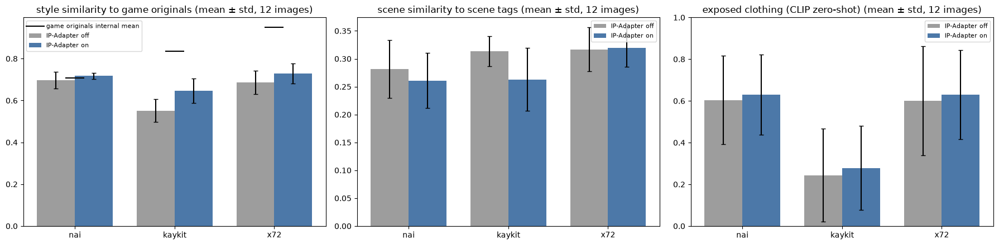

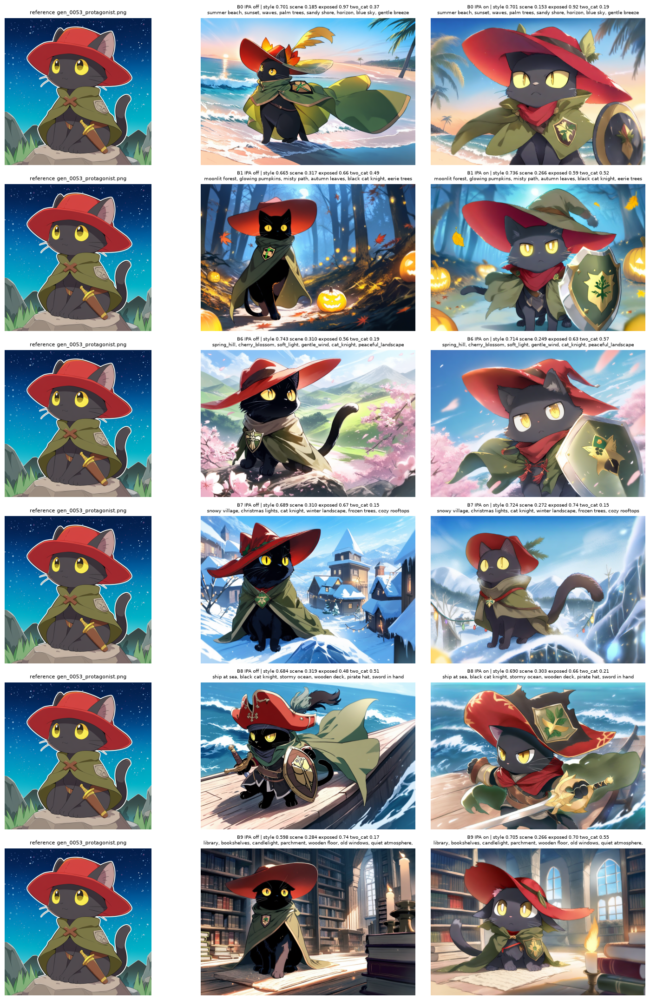

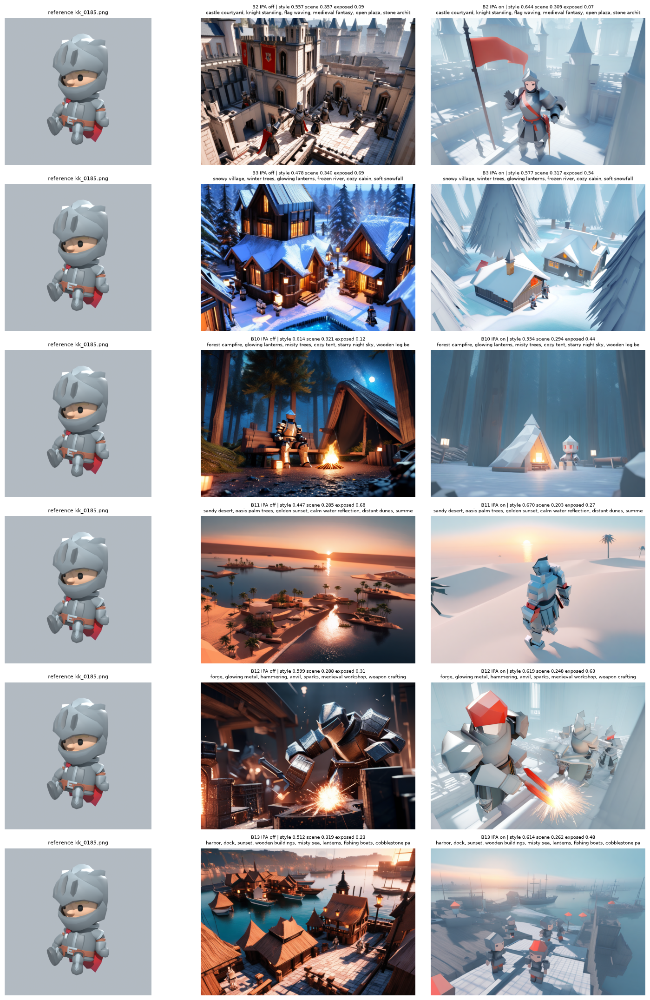

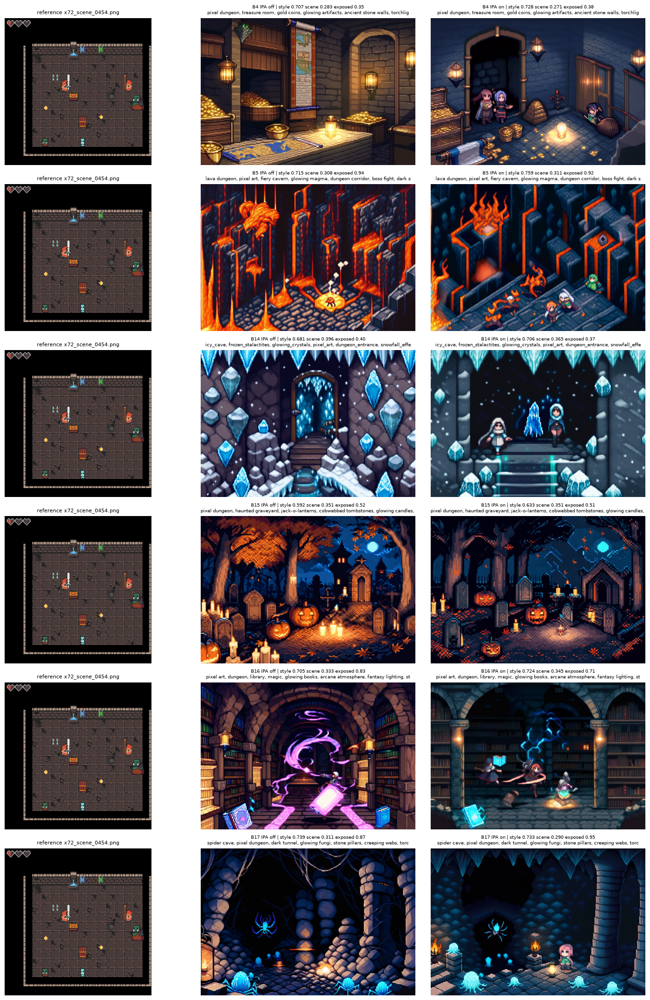

In [4]:
games = ['nai', 'kaykit', 'x72']
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
x = np.arange(len(games))
for k, (use, color, lab) in enumerate([(False, '#9D9D9D', 'IP-Adapter off'), (True, '#4C78A8', 'IP-Adapter on')]):
    for ax, col in zip(axes, ['style_sim', 'scene_sim', 'exposed_prob']):
        v = [cs[(cs.game == g) & (cs.use_ipa == use)][col] for g in games]
        ax.bar(x + (k - 0.5) * 0.38, [s.mean() for s in v], 0.38, yerr=[s.std() for s in v], capsize=3, color=color, label=lab)
axes[0].scatter(x, [held_base[g] for g in games], color='black', marker='_', s=600, zorder=3, label='game originals internal mean')
for ax, title in zip(axes, ['style similarity to game originals', 'scene similarity to scene tags',
                            'exposed clothing (CLIP zero-shot)']):
    ax.set_xticks(x, games)
    ax.set_title(f'{title} (mean ± std, {int(cs.groupby(["game", "use_ipa"]).size().iloc[0])} images)')
    ax.legend(fontsize=8)
axes[2].set_ylim(0, 1)
plt.tight_layout()
plt.savefig(OUT_DIR / 'c_scores.png', dpi=90)
plt.show()

# 게임별 그림 (seed 0): 행 = 요청, 열 = 참조 이미지 / IP-Adapter 끔 / 켬
for g in games:
    items = list(SCENES[SCENES.game == g]['item'])
    fig, axes = plt.subplots(len(items), 3, figsize=(15, 3.6 * len(items)), squeeze=False)
    for i, it in enumerate(items):
        axes[i, 0].imshow(Image.open(REFS[g]).convert('RGB'))
        axes[i, 0].set_title(f'reference {REFS[g].name}', fontsize=8)
        for j, use in enumerate([False, True]):
            r = cs[(cs['item'] == it) & (cs.seed == 0) & (cs.use_ipa == use)]
            if len(r):
                r = r.iloc[0]
                axes[i, j + 1].imshow(Image.open(OUT_DIR / r.file))
                extra = f' two_cat {r.two_cat_prob:.2f}' if g == 'nai' else ''
                axes[i, j + 1].set_title(f"{it} {'IPA on' if use else 'IPA off'} | style {r.style_sim:.3f} scene {r.scene_sim:.3f} "
                                         f"exposed {r.exposed_prob:.2f}{extra}\n{r.scene[:90]}", fontsize=7)
        for ax in axes[i]:
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'c_grid_{g}.png', dpi=50)
    plt.show()